## Working with Time Series

Three flavors of date/time data:
- **Time stamps** — a specific moment (e.g. July 4th, 2015, 7:00am)
- **Time deltas / durations** — an exact length of time (e.g. 22.56 seconds)
- **Time periods** — a length of time between a start/end (e.g. "the year 2015")

Pandas builds a unified toolkit for all three, combining Python's `datetime` 
(flexible, slow) with NumPy's `datetime64` (fast, rigid) into the best of both.

## Three layers, from slow/flexible to fast/rigid

1. **Python's `datetime`/`dateutil`** — easy to use, parses almost any string 
   format, but doesn't scale (just like plain Python lists of numbers vs. NumPy arrays).
2. **NumPy's `datetime64`** — compact, vectorized, fast — but requires a strict 
   input format and lacks convenience methods.
3. **Pandas' `Timestamp`/`DatetimeIndex`** — combines both: `datetime`'s ease 
   of use with `datetime64`'s speed.

In [1]:
from datetime import datetime
datetime(year=2015, month=7, day=4)



datetime.datetime(2015, 7, 4, 0, 0)

In [2]:
from dateutil import parser
date = parser.parse("4th of July, 2015")
date.strftime('%A')     # 'Saturday'



'Saturday'

In [3]:
import numpy as np
date = np.array('2015-07-04', dtype=np.datetime64)
date + np.arange(12)     # vectorized — fast, but np.datetime64 has few built-in convenience methods



array(['2015-07-04', '2015-07-05', '2015-07-06', '2015-07-07',
       '2015-07-08', '2015-07-09', '2015-07-10', '2015-07-11',
       '2015-07-12', '2015-07-13', '2015-07-14', '2015-07-15'],
      dtype='datetime64[D]')

In [4]:
import pandas as pd
date = pd.to_datetime("4th of July, 2015")   # flexible parsing, like dateutil
date.strftime('%A')                             # 'Saturday'
date + pd.to_timedelta(np.arange(12), 'D')       # vectorized, like NumPy

DatetimeIndex(['2015-07-04', '2015-07-05', '2015-07-06', '2015-07-07',
               '2015-07-08', '2015-07-09', '2015-07-10', '2015-07-11',
               '2015-07-12', '2015-07-13', '2015-07-14', '2015-07-15'],
              dtype='datetime64[us]', freq=None)

## datetime64's resolution/range tradeoff

`datetime64` is a 64-bit integer under a chosen fundamental unit (day, second, 
nanosecond, ...). More precision = smaller total range it can represent — e.g. 
nanosecond precision only covers ~584 years total. Pandas' practical default is 
`datetime64[ns]` — fine-grained enough for most real data, wide enough range.

## Indexing a Series by timestamp

Once a Series/DataFrame uses a `DatetimeIndex`, all the normal Series indexing 
patterns work — but so does natural date-string slicing, and even slicing by 
just a year.

In [5]:
index = pd.DatetimeIndex(['2014-07-04', '2014-08-04', '2015-07-04', '2015-08-04'])
data = pd.Series([0, 1, 2, 3], index=index)

data['2014-07-04':'2015-07-04']    # slice by date string, INCLUSIVE on both ends
data['2015']                          # special: slice ALL data from that year

2015-07-04    2
2015-08-04    3
dtype: int64

## The three core time series types

| Concept | Pandas type | Index type | Built on |
|---|---|---|---|
| Time stamp | `Timestamp` | `DatetimeIndex` | `numpy.datetime64` |
| Time period | `Period` | `PeriodIndex` | `numpy.datetime64` |
| Time delta | `Timedelta` | `TimedeltaIndex` | `numpy.timedelta64` |

Usually created via `pd.to_datetime()` rather than the classes directly — 
it parses flexible formats and returns the right type automatically.

In [6]:
dates = pd.to_datetime([datetime(2015, 7, 3), '4th of July, 2015',
                         '2015-Jul-6', '07-07-2015', '20150708'])
# -> a DatetimeIndex, despite wildly different input formats

dates.to_period('D')    # DatetimeIndex -> PeriodIndex, given a frequency code

dates - dates[0]          # subtracting dates -> TimedeltaIndex, automatically

TimedeltaIndex(['0 days', '1 days', '3 days', '4 days', '5 days'], dtype='timedelta64[us]', freq=None)

## Building regular sequences with date_range / period_range / timedelta_range

Same idea as `range()` / `np.arange()`, but for dates. Give either a 
(start, stop) pair or a (start, periods) pair, plus an optional frequency code.

In [9]:
pd.date_range('2015-07-03', '2015-07-10')          # daily by default
pd.date_range('2015-07-03', periods=8)               # start + count, instead of start + stop
pd.date_range('2015-07-03', periods=8, freq='h')      # hourly spacing

pd.period_range('2015-07', periods=8, freq='M')        # monthly periods
pd.timedelta_range(0, periods=10, freq='h')              # sequence of durations

TimedeltaIndex(['0 days 00:00:00', '0 days 01:00:00', '0 days 02:00:00',
                '0 days 03:00:00', '0 days 04:00:00', '0 days 05:00:00',
                '0 days 06:00:00', '0 days 07:00:00', '0 days 08:00:00',
                '0 days 09:00:00'],
               dtype='timedelta64[ns]', freq='h')

## Frequency codes — reference table (Pandas 3.x)

| Code | Meaning | Code | Meaning |
|---|---|---|---|
| `D` | Calendar day | `B` | Business day |
| `W` | Weekly | | |
| `ME` | Month end | `BME` | Business month end |
| `QE` | Quarter end | `BQE` | Business quarter end |
| `YE` | Year end | `BYE` | Business year end |
| `h` | Hours | `bh` | Business hours |
| `min` | Minutes | | |
| `s` | Seconds | | |
| `ms` | Milliseconds | | |
| `us` | Microseconds | | |
| `ns` | Nanoseconds | | |

**Add `S` suffix** (`MS`, `QS`, `YS`) → marks the *start* of the period instead 
of the end. **Add a month/weekday suffix** (`QE-JAN`, `W-SUN`) → shifts where 
the period boundary falls. **Combine codes with numbers** for custom spacing 
(e.g. `'2h30min'` = 2.5 hours).

**Old vs. new, for reference when reading older tutorials/books:**

| Old (pre-2.2, removed in 3.x) | New |
|---|---|
| `H` | `h` |
| `T` | `min` |
| `S` | `s` |
| `L` | `ms` |
| `U` | `us` |
| `N` | `ns` |
| `A` (year end) | `YE` |
| `M` (month end) | `ME` |
| `Q` (quarter end) | `QE` |
| `BA`/`BY` (business year end) | `BYE` |

The day-based and business-day codes (`D`, `B`, `W`) are unchanged — only the 
sub-daily and annual/monthly/quarterly ones were renamed.

## Resampling vs. asfreq — the key distinction

Both change a time series' frequency, but conceptually differ:
- **`resample()`** — a data **aggregation**. Computes a summary (mean, sum, ...) 
  over each new interval.
- **`asfreq()`** — a data **selection**. Just picks out the value that falls 
  exactly on each new interval boundary — no computation, some points may be dropped.

Down-sampling (e.g. daily → yearly): `resample().mean()` gives the *average 
over the year*; `asfreq()` gives *whatever the value was at that exact instant*.

In [10]:
goog.resample('BA').mean()   # aggregation -> average of the whole period
goog.asfreq('BA')              # selection -> value exactly at that point

NameError: name 'goog' is not defined

## Why this matters for energy time series

Hourly demand/PV data is exactly this kind of indexed time series. 
`resample()` is the natural tool for turning raw hourly readings into daily 
or monthly summaries for reporting (`.resample('D').sum()` for daily 
consumption totals), while `date_range()` is the standard way to build a 
clean, regular hourly index to align sensor data against — especially useful 
when raw timestamps are irregular or contain gaps.

# Real Data and Visualization

In [12]:
pip install yfinance --break-system-packages


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 61.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [yfinance]4/7 [peewee]
Note: you may need to restart the kernel to use updated packages.


In [13]:
import yfinance as yf

goog = yf.download('GOOG', start='2004-01-01', end='2016-01-01')
goog.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2004-08-19,2.477291,2.569133,2.369154,2.468896,897427216
2004-08-20,2.674062,2.693073,2.481242,2.493833,458857488
2004-08-23,2.700973,2.801704,2.692332,2.734303,366857939
2004-08-24,2.589133,2.755289,2.557037,2.746401,306396159
2004-08-25,2.617030,2.666409,2.564690,2.591354,184645512


In [14]:
goog.columns

MultiIndex([( 'Close', 'GOOG'),
            (  'High', 'GOOG'),
            (   'Low', 'GOOG'),
            (  'Open', 'GOOG'),
            ('Volume', 'GOOG')],
           names=['Price', 'Ticker'])

In [17]:
goog_close = goog['Close']['GOOG']
goog_close.head()

Date
2004-08-19    2.477291
2004-08-20    2.674062
2004-08-23    2.700973
2004-08-24    2.589133
2004-08-25    2.617030
Name: GOOG, dtype: float64

In [23]:
goog.columns = goog.columns.droplevel('Ticker')
goog.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2004-08-19,2.477291,2.569133,2.369154,2.468896,897427216
2004-08-20,2.674062,2.693073,2.481242,2.493833,458857488
2004-08-23,2.700973,2.801704,2.692332,2.734303,366857939
2004-08-24,2.589133,2.755289,2.557037,2.746401,306396159
2004-08-25,2.617030,2.666409,2.564690,2.591354,184645512


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

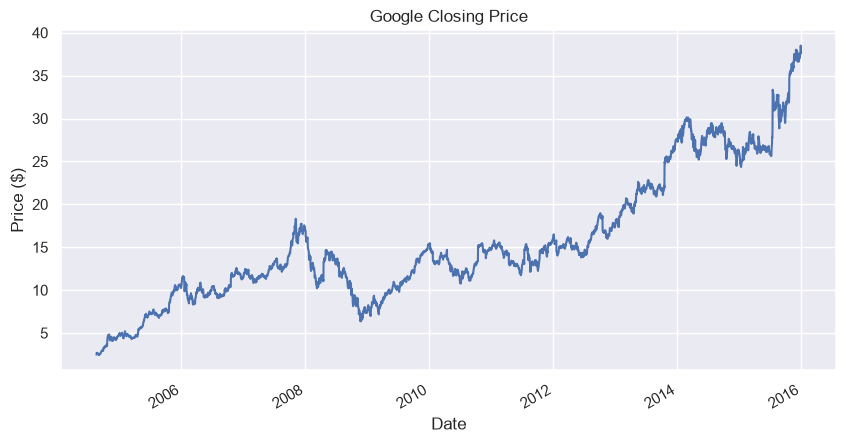

In [25]:
goog['Close'].plot(figsize=(10,5), title = "Google Closing Price")
plt.ylabel('Price ($)')
plt.show()

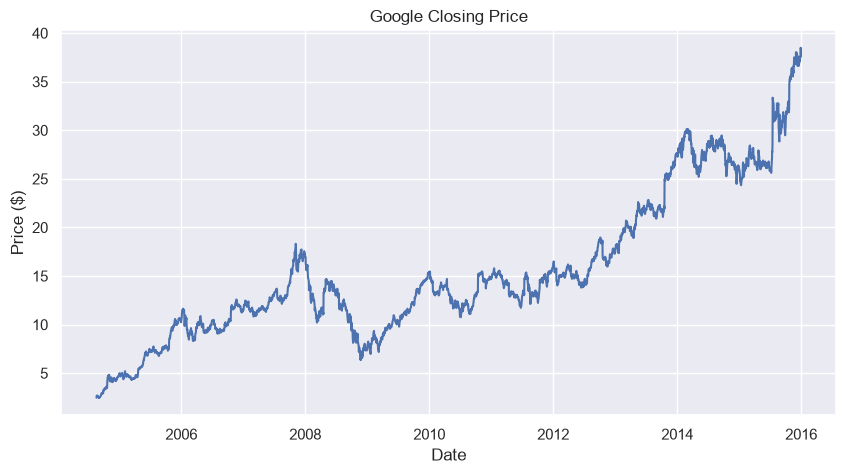

In [ ]:
# Pure matplotlib — same plot, more explicit control
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(goog.index, goog['Close'])
ax.set_title('Google Closing Price')
ax.set_xlabel('Date')
ax.set_ylabel('Price ($)')
plt.show()

## Comparing resample vs. asfreq visually — recreating the book's example

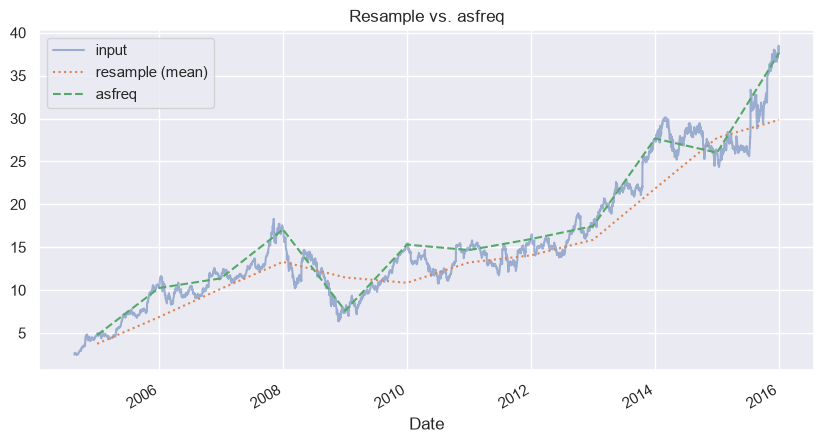

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

goog['Close'].plot(ax=ax, alpha=0.5, style='-', label='input')
goog['Close'].resample('BYE').mean().plot(ax=ax, style=':', label='resample (mean)')
goog['Close'].asfreq('BYE').plot(ax=ax, style='--', label='asfreq')

ax.legend()
ax.set_title('Resample vs. asfreq')
plt.show()

## Multiple related series on one plot — e.g. Close vs. a rolling average

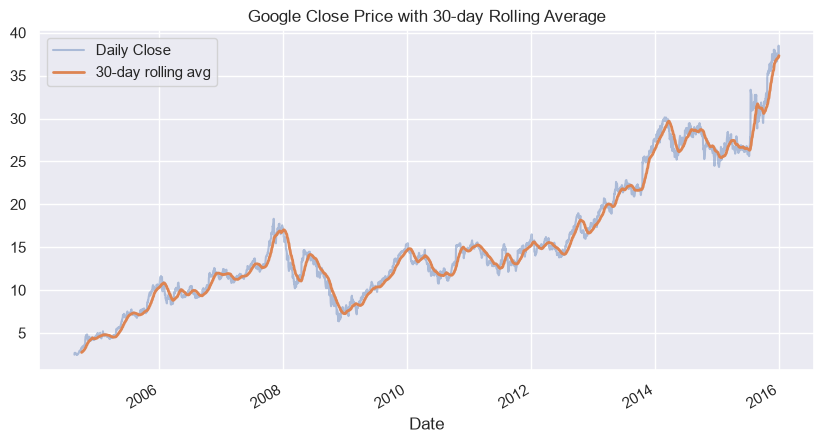

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))

goog['Close'].plot(ax=ax, label='Daily Close', alpha=0.4)
goog['Close'].rolling(window=30).mean().plot(ax=ax, label='30-day rolling avg', linewidth=2)

ax.legend()
ax.set_title('Google Close Price with 30-day Rolling Average')
plt.show()

## Where seaborn actually adds value — distributions and relationships

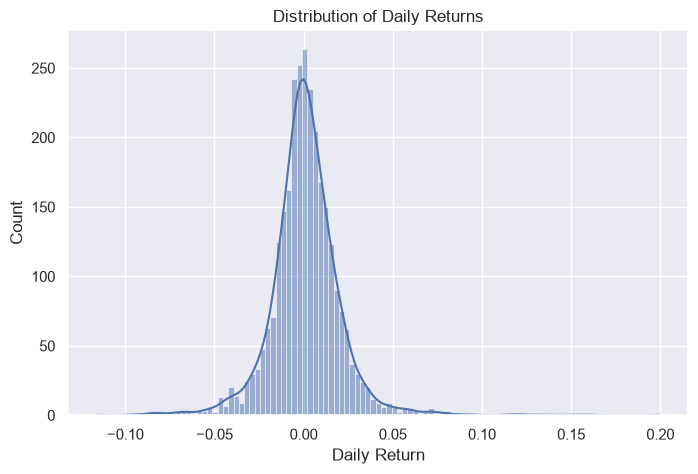

In [29]:
daily_returns = goog['Close'].pct_change().dropna()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(daily_returns, kde=True, ax=ax)
ax.set_title('Distribution of Daily Returns')
ax.set_xlabel('Daily Return')
plt.show()